# 20nodes_EB_obsconf0_latconf0_Gaussian_Mixed: tuned



In [1]:
from pathlib import Path
import sys, os, json
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "experiments/run_model.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the repository.")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "experiments")]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import final_visualization as fv
import result_tables as th
fv.apply_style()
th.ensure_output_dirs("tuned")
from scipy.stats import spearmanr
from varsortability import calculate_varsortability
from condition_data import load_sample, sample_path


def sortability(frame, study):
    rows = []
    for family, seed in (
        frame[["dataset", "dataset_seed"]].drop_duplicates().itertuples(index=False, name=None)
    ):
        path = sample_path({"tuned": "evaluation"}.get(study, study), family)
        with load_sample(study, family, int(seed)) as data:
            raw = "X_raw" in data.files
            result = calculate_varsortability(data["X_raw"] if raw else data["X"], data["true_adj"])
            if not raw:
                for key in (
                    "varsortability",
                    "n_ordered_variance_paths",
                    "n_tied_variance_paths",
                ):
                    result[key] = np.nan
        rows.append(
            dict(
                dataset=family,
                dataset_seed=seed,
                study=study,
                raw_variance_available=raw,
                sample_path=str(path.relative_to(ROOT)),
                **result,
            )
        )
    return pd.DataFrame(rows)


In [2]:


output = ROOT / "results"
output.mkdir(parents=True, exist_ok=True)
sources = th.load_aligned_sources()
main = sources["benchmark_with_biological"]
complete = sources["complete"]
correlations = []
(output / "tuned" / "by_family" / '20nodes_EB_obsconf0_latconf0_Gaussian_Mixed').mkdir(parents=True, exist_ok=True)


## Metrics, seed stability and sortability


,model,mean,std,size
0,AVICI,0.444043,0.068876,15
1,DAGMA_Linear,0.307548,0.090113,15
2,DAGMA_Nonlinear,0.216006,0.098873,15
3,DAS,0.262122,0.095902,15
4,DirectLiNGAM,0.171156,0.083761,15
5,FCI,0.204461,0.076567,15
6,GES,0.524452,0.103182,15
7,GOLEM,0.406847,0.092176,15
8,GRaSP,0.592948,0.071041,15
9,GraNDAG,0.312748,0.188411,15


,model,mean,std,size
0,AVICI,42.800000,5.212622,15
1,DAGMA_Linear,48.200000,9.305912,15
2,DAGMA_Nonlinear,52.706667,9.932017,15
3,DAS,65.200000,16.536540,15
4,DirectLiNGAM,62.600000,12.205385,15
5,FCI,47.240000,8.206339,15
6,GES,40.733333,16.060007,15
7,GOLEM,44.733333,7.353004,15
8,GRaSP,33.786667,6.057565,15
9,GraNDAG,49.466667,12.944203,15


,model,mean,std,size
0,AVICI,0.809149,0.095856,15
1,DAGMA_Linear,0.487370,0.133273,15
2,DAGMA_Nonlinear,0.565619,0.253159,15
3,DAS,0.276130,0.113771,15
4,DirectLiNGAM,0.213981,0.107062,15
5,FCI,0.867937,0.106950,15
6,GES,0.720870,0.202272,15
7,GOLEM,0.622962,0.141041,15
8,GRaSP,0.809955,0.083977,15
9,GraNDAG,0.659563,0.240311,15


,model,mean,std,size
0,AVICI,0.313399,0.073033,15
1,DAGMA_Linear,0.225912,0.069821,15
2,DAGMA_Nonlinear,0.135526,0.063844,15
3,DAS,0.253016,0.082926,15
4,DirectLiNGAM,0.144679,0.071511,15
5,FCI,0.118551,0.050148,15
6,GES,0.423521,0.074525,15
7,GOLEM,0.305888,0.078414,15
8,GRaSP,0.474964,0.086105,15
9,GraNDAG,0.235775,0.187306,15


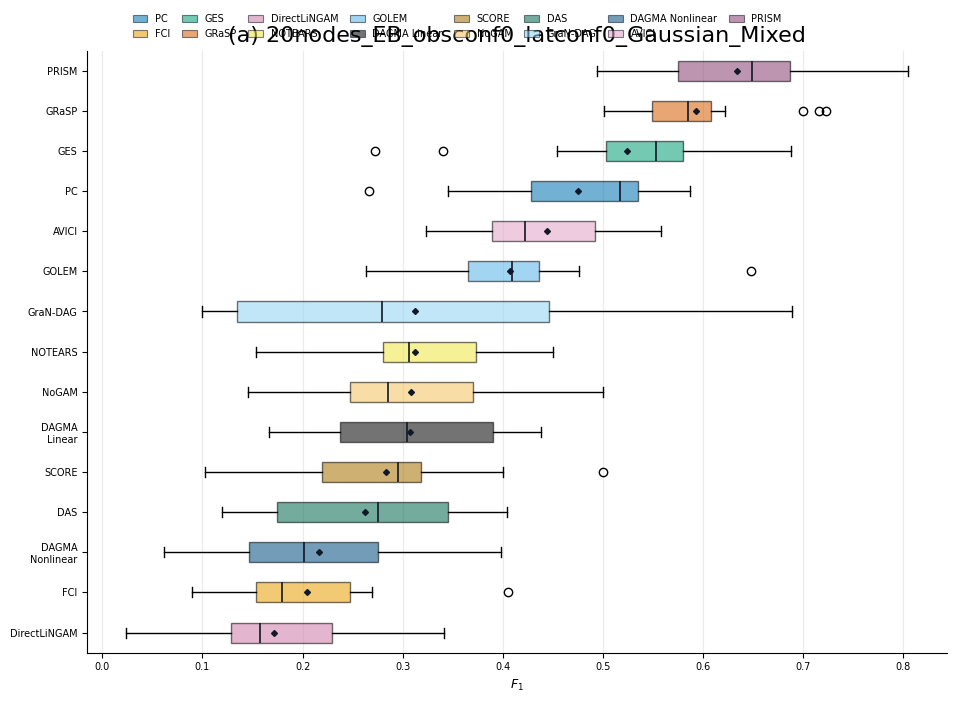

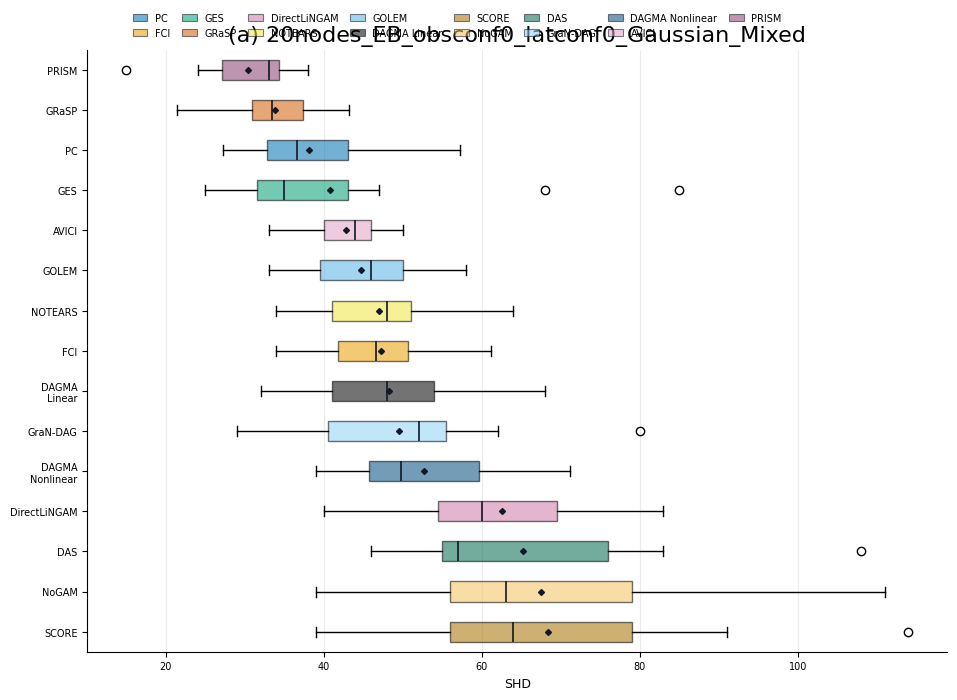

,dataset_seed,model,f1_range
0,19,AVICI,0.000000
1,19,DAGMA_Linear,0.000000
2,19,DAGMA_Nonlinear,0.027289
3,19,DAS,0.000000
4,19,DirectLiNGAM,0.000000
5,19,FCI,0.193081
6,19,GES,0.000000
7,19,GOLEM,0.000000
8,19,GRaSP,0.089258
9,19,GraNDAG,0.000000


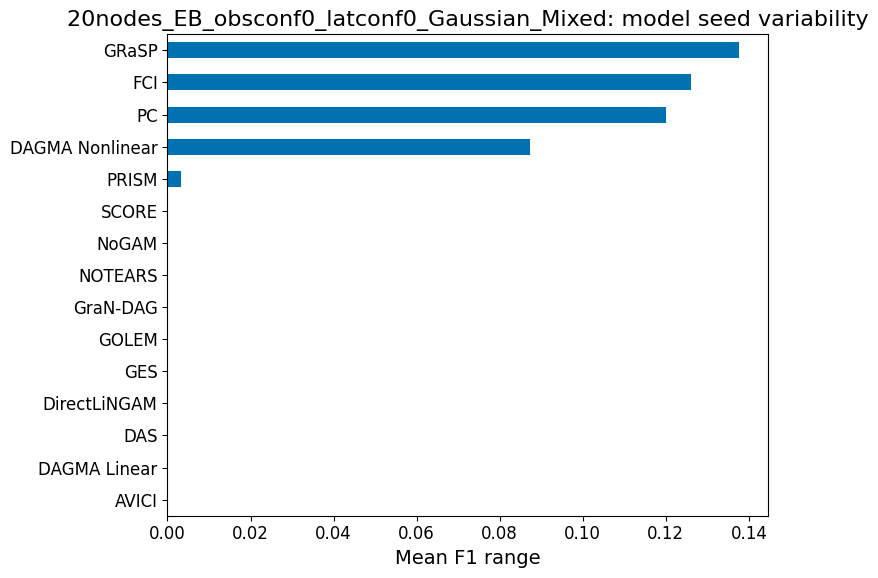

,model_seed,model,f1_range
0,0,AVICI,0.234163
1,0,DAGMA_Linear,0.271689
2,0,DAGMA_Nonlinear,0.306215
3,0,DAS,0.284993
4,0,DirectLiNGAM,0.317367
5,0,FCI,0.402256
6,0,GES,0.415445
7,0,GOLEM,0.384461
8,0,GRaSP,0.239938
9,0,GraNDAG,0.589076


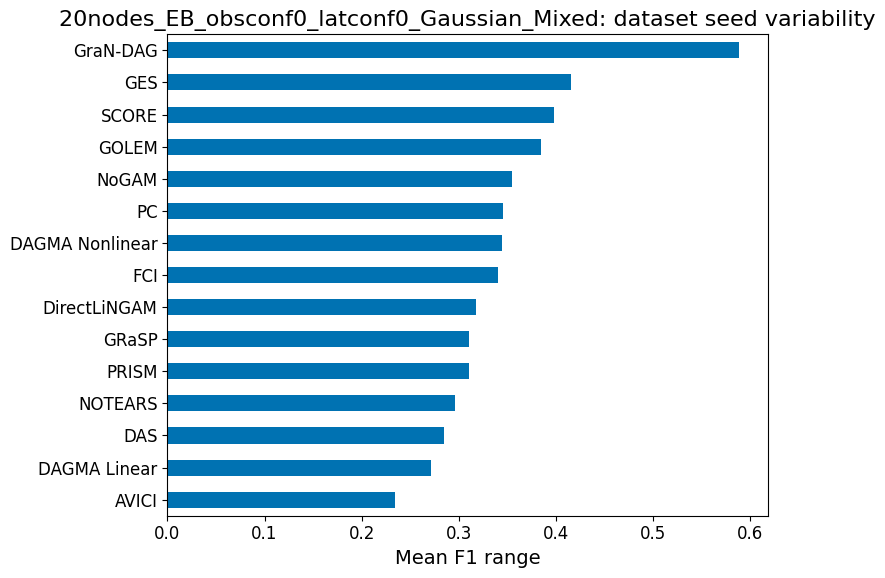

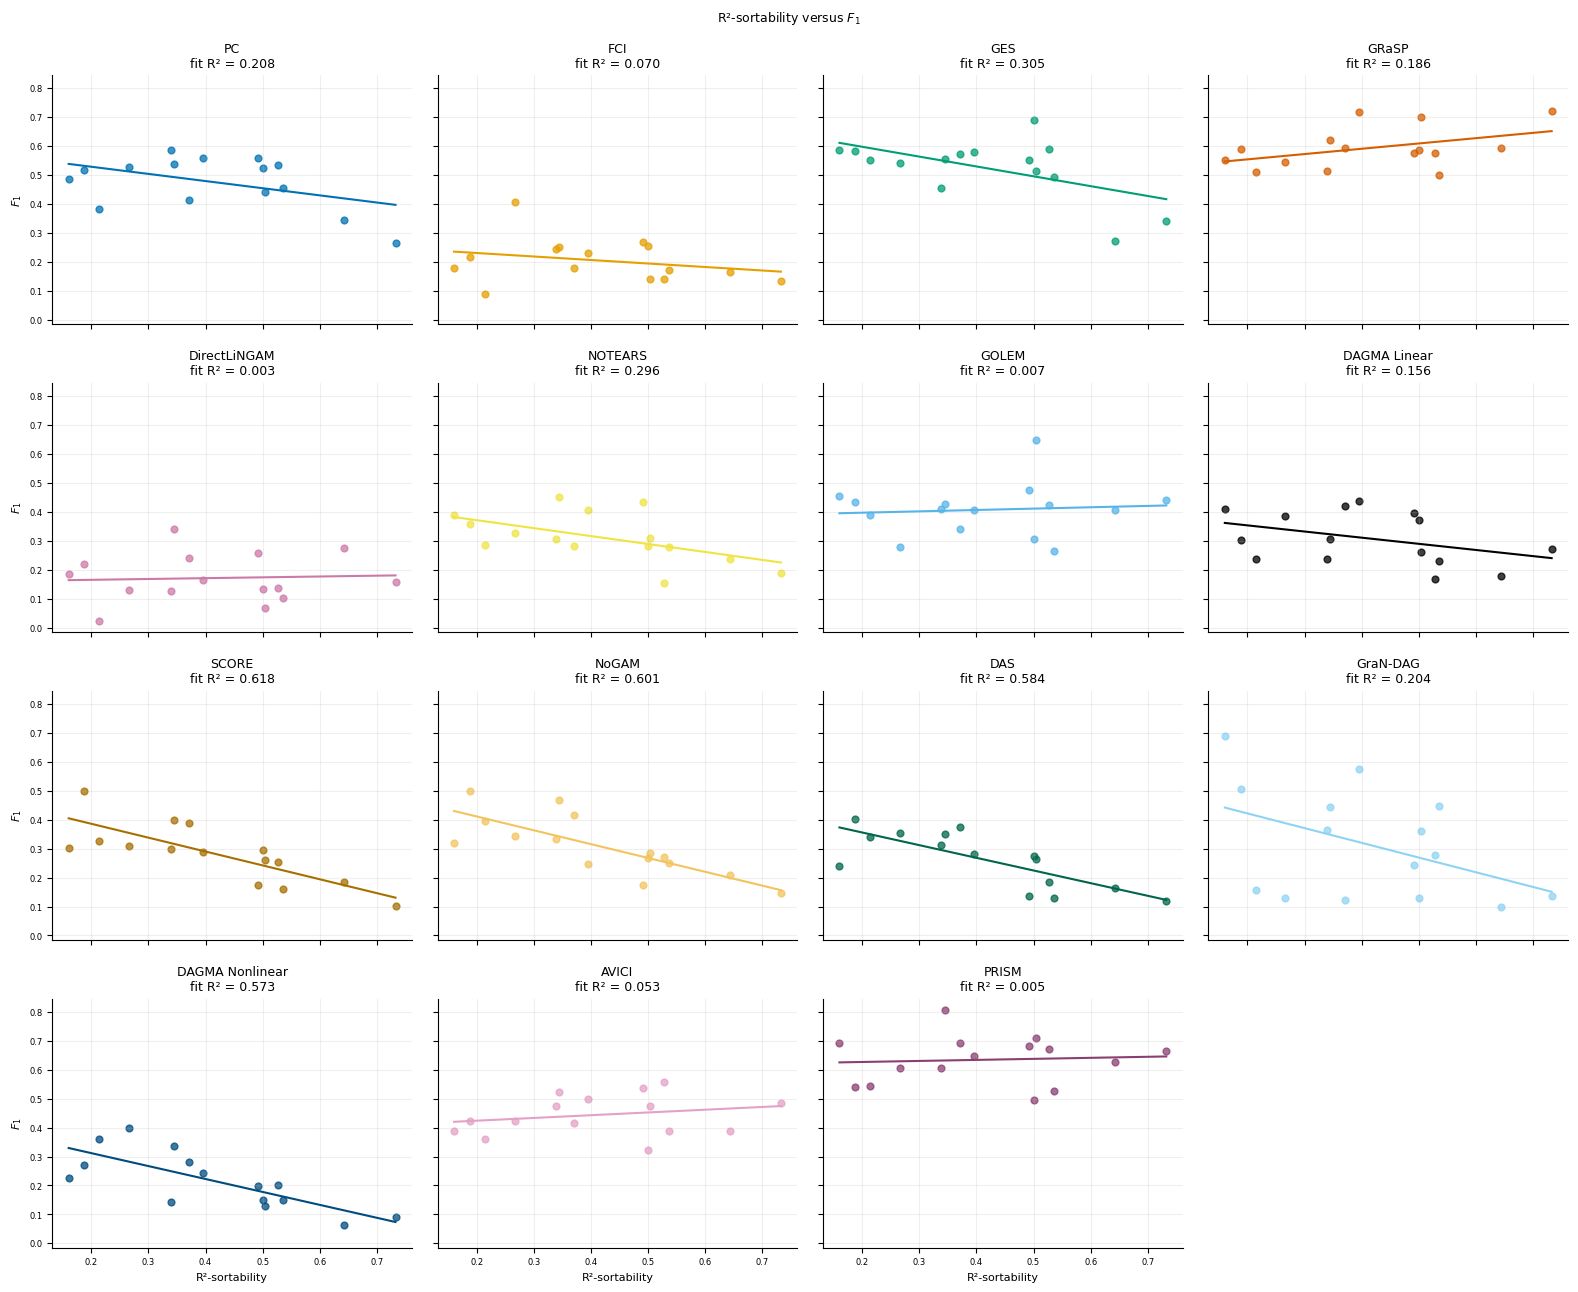

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,AVICI,0.389610,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
1,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,DAGMA_Linear,0.177215,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
2,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,DAGMA_Nonlinear,0.061875,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
3,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,DAS,0.165289,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
4,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,DirectLiNGAM,0.276596,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
5,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,FCI,0.164431,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
6,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,GES,0.272727,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
7,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,GOLEM,0.404762,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
8,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,GRaSP,0.594322,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
9,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,GraNDAG,0.100000,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,19,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
1,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,47,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.830189,0.535849,265,220,0,142,0,20,2000
2,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,50,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.857494,0.732187,407,349,0,298,0,20,2000
3,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,52,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.906250,0.503906,256,232,0,129,0,20,2000
4,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,71,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.682008,0.338912,239,163,0,81,0,20,2000
5,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,75,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.730878,0.371105,353,258,0,131,0,20,2000
6,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,77,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.675958,0.188153,287,194,0,54,0,20,2000
7,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,102,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.660232,0.266409,259,171,0,69,0,20,2000
8,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,125,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.889655,0.344828,145,129,0,50,0,20,2000
9,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,158,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.808290,0.160622,193,156,0,31,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,0.230756,0.053248,0.094946,0.404716,0.407990,0.216265,0.438839
1,DAGMA_Linear,15,-0.394991,0.156018,-0.212633,0.395623,0.145084,-0.428571,0.110960
2,DAGMA_Nonlinear,15,-0.757028,0.573092,-0.447139,0.401215,0.001084,-0.728571,0.002065
3,DAS,15,-0.764289,0.584138,-0.437864,0.443489,0.000907,-0.735714,0.001770
4,DirectLiNGAM,15,0.057329,0.003287,0.028686,0.159274,0.839183,-0.003571,0.989921
5,FCI,15,-0.264376,0.069895,-0.120926,0.254550,0.341002,-0.339286,0.216029
6,GES,15,-0.552102,0.304817,-0.340313,0.665413,0.032845,-0.392857,0.147467
7,GOLEM,15,0.085312,0.007278,0.046977,0.387389,0.762423,-0.042857,0.879460
8,GRaSP,15,0.431710,0.186373,0.183212,0.517060,0.108086,0.371429,0.172850
9,GraNDAG,15,-0.451941,0.204251,-0.508677,0.523447,0.090789,-0.371429,0.172850


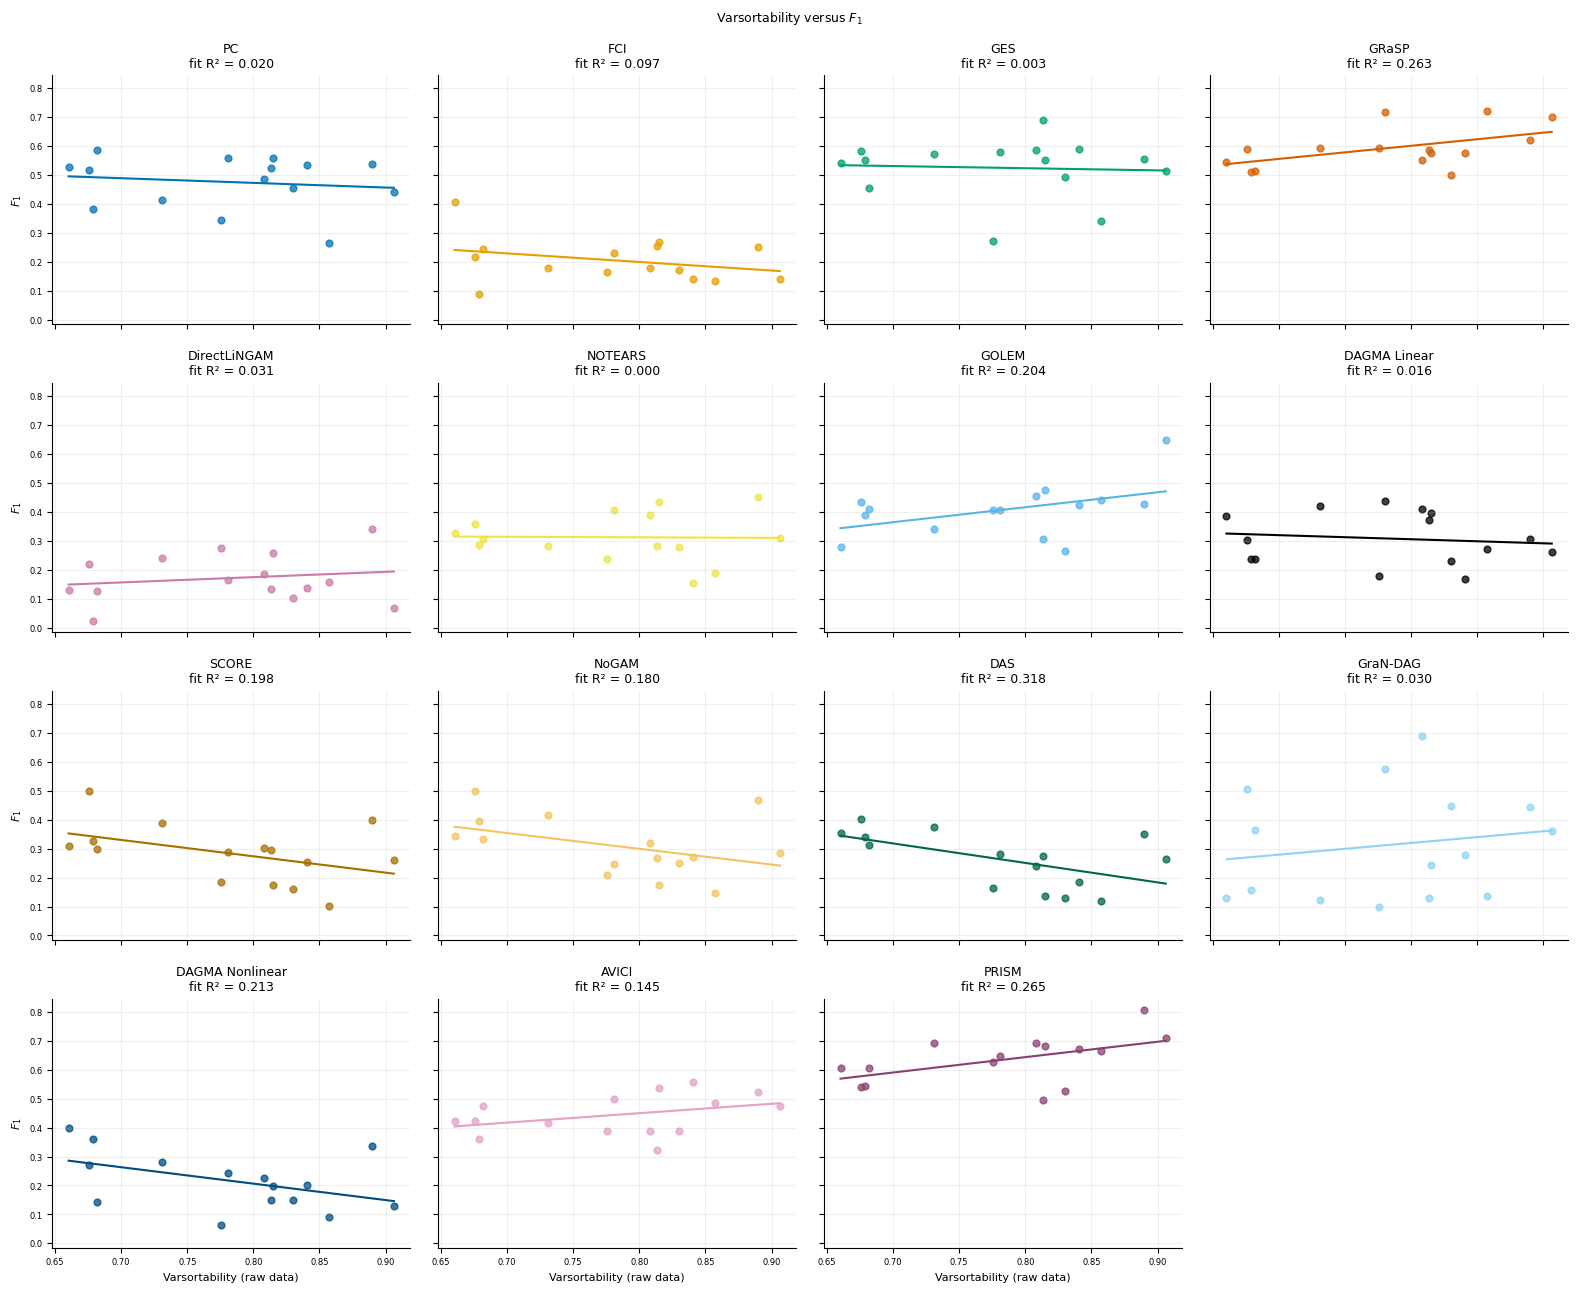

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,AVICI,0.389610,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
1,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,DAGMA_Linear,0.177215,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
2,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,DAGMA_Nonlinear,0.061875,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
3,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,DAS,0.165289,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
4,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,DirectLiNGAM,0.276596,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
5,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,FCI,0.164431,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
6,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,GES,0.272727,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
7,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,GOLEM,0.404762,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
8,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,GRaSP,0.594322,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
9,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,GraNDAG,0.100000,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,19,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
1,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,47,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.830189,0.535849,265,220,0,142,0,20,2000
2,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,50,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.857494,0.732187,407,349,0,298,0,20,2000
3,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,52,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.906250,0.503906,256,232,0,129,0,20,2000
4,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,71,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.682008,0.338912,239,163,0,81,0,20,2000
5,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,75,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.730878,0.371105,353,258,0,131,0,20,2000
6,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,77,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.675958,0.188153,287,194,0,54,0,20,2000
7,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,102,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.660232,0.266409,259,171,0,69,0,20,2000
8,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,125,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.889655,0.344828,145,129,0,50,0,20,2000
9,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,158,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.808290,0.160622,193,156,0,31,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,0.380151,0.144515,0.325337,0.189313,0.162194,0.402145,0.137288
1,DAGMA_Linear,15,-0.125650,0.015788,-0.140688,0.417704,0.655454,-0.171429,0.541272
2,DAGMA_Nonlinear,15,-0.461698,0.213165,-0.567205,0.660112,0.083189,-0.460714,0.083933
3,DAS,15,-0.564309,0.318445,-0.672434,0.788621,0.028424,-0.603571,0.017200
4,DirectLiNGAM,15,0.175888,0.030936,0.183056,0.027828,0.530639,0.064286,0.819948
5,FCI,15,-0.311013,0.096729,-0.295889,0.436134,0.259185,-0.253571,0.361816
6,GES,15,-0.058278,0.003396,-0.074716,0.582953,0.836555,-0.021429,0.939578
7,GOLEM,15,0.451382,0.203745,0.516974,0.002070,0.091239,0.453571,0.089486
8,GRaSP,15,0.513064,0.263234,0.452882,0.238353,0.050479,0.417857,0.121173
9,GraNDAG,15,0.172457,0.029741,0.403731,-0.003363,0.538812,0.175000,0.532748


,model,mean,std,size
0,AVICI,0.478489,0.056528,15
1,DAGMA_Linear,0.142143,0.074931,15
2,DAGMA_Nonlinear,0.290933,0.061099,15
3,DAS,0.283281,0.102784,15
4,DirectLiNGAM,0.187143,0.089254,15
5,FCI,0.163014,0.071825,15
6,GES,0.555136,0.111798,15
7,GOLEM,0.136962,0.057750,15
8,GRaSP,0.592948,0.071041,15
9,GraNDAG,0.043644,0.039965,15


,model,mean,std,size
0,AVICI,44.666667,5.924123,15
1,DAGMA_Linear,57.466667,8.517769,15
2,DAGMA_Nonlinear,50.826667,6.839326,15
3,DAS,68.466667,17.995502,15
4,DirectLiNGAM,83.733333,19.326025,15
5,FCI,52.080000,10.680503,15
6,GES,43.133333,18.863671,15
7,GOLEM,63.400000,9.272078,15
8,GRaSP,33.786667,6.057565,15
9,GraNDAG,55.600000,5.877317,15


,model,mean,std,size
0,AVICI,0.675820,0.102991,15
1,DAGMA_Linear,0.248472,0.124042,15
2,DAGMA_Nonlinear,0.473046,0.098101,15
3,DAS,0.276593,0.112272,15
4,DirectLiNGAM,0.163962,0.080828,15
5,FCI,0.884408,0.175883,15
6,GES,0.592342,0.164279,15
7,GOLEM,0.199013,0.090868,15
8,GRaSP,0.809955,0.083977,15
9,GraNDAG,0.429444,0.336987,15


,model,mean,std,size
0,AVICI,0.383048,0.085055,15
1,DAGMA_Linear,0.102466,0.056637,15
2,DAGMA_Nonlinear,0.214046,0.052664,15
3,DAS,0.293754,0.096052,15
4,DirectLiNGAM,0.222105,0.105168,15
5,FCI,0.091729,0.043069,15
6,GES,0.537827,0.089758,15
7,GOLEM,0.107663,0.047114,15
8,GRaSP,0.474964,0.086105,15
9,GraNDAG,0.023884,0.023459,15


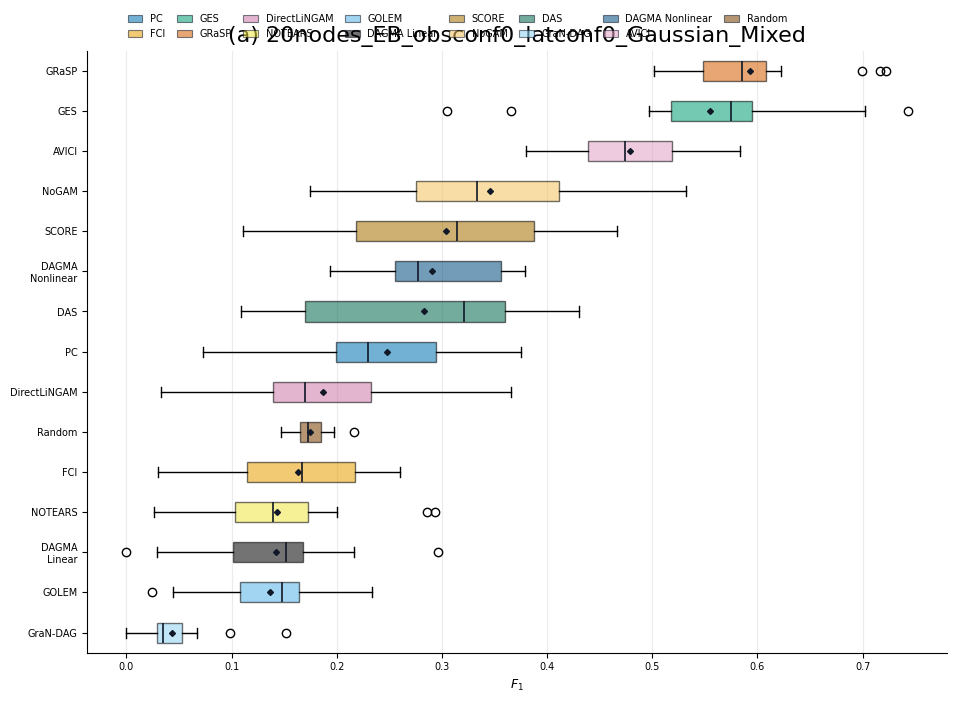

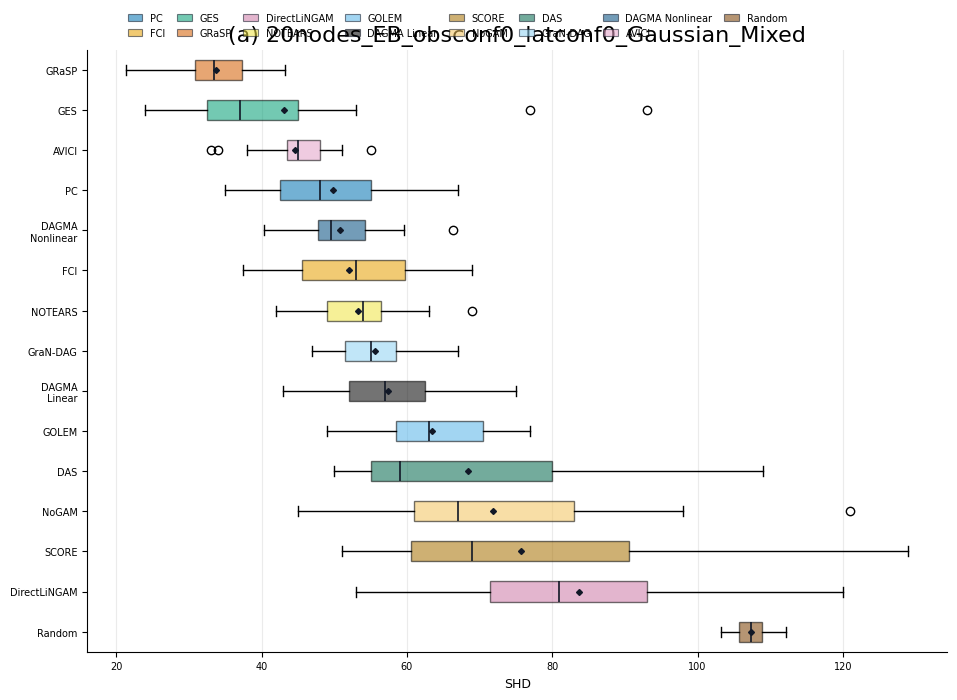

,dataset_seed,model,f1_range
0,19,AVICI,0.000000
1,19,DAGMA_Linear,0.000000
2,19,DAGMA_Nonlinear,0.190789
3,19,DAS,0.000000
4,19,DirectLiNGAM,0.000000
5,19,FCI,0.000000
6,19,GES,0.000000
7,19,GOLEM,0.000000
8,19,GRaSP,0.089258
9,19,GraNDAG,0.000000


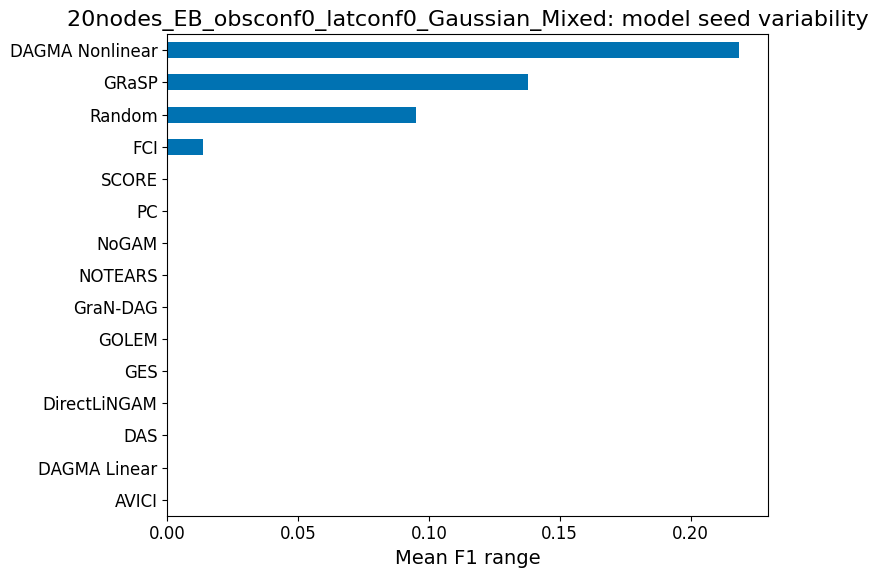

,model_seed,model,f1_range
0,0,AVICI,0.203586
1,0,DAGMA_Linear,0.296296
2,0,DAGMA_Nonlinear,0.343228
3,0,DAS,0.320816
4,0,DirectLiNGAM,0.331884
5,0,FCI,0.287218
6,0,GES,0.439015
7,0,GOLEM,0.209670
8,0,GRaSP,0.239938
9,0,GraNDAG,0.151899


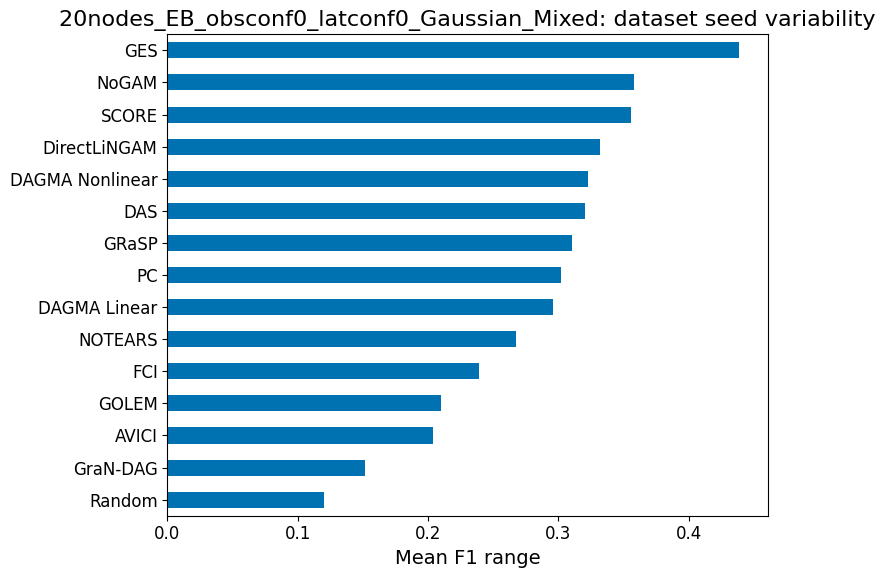

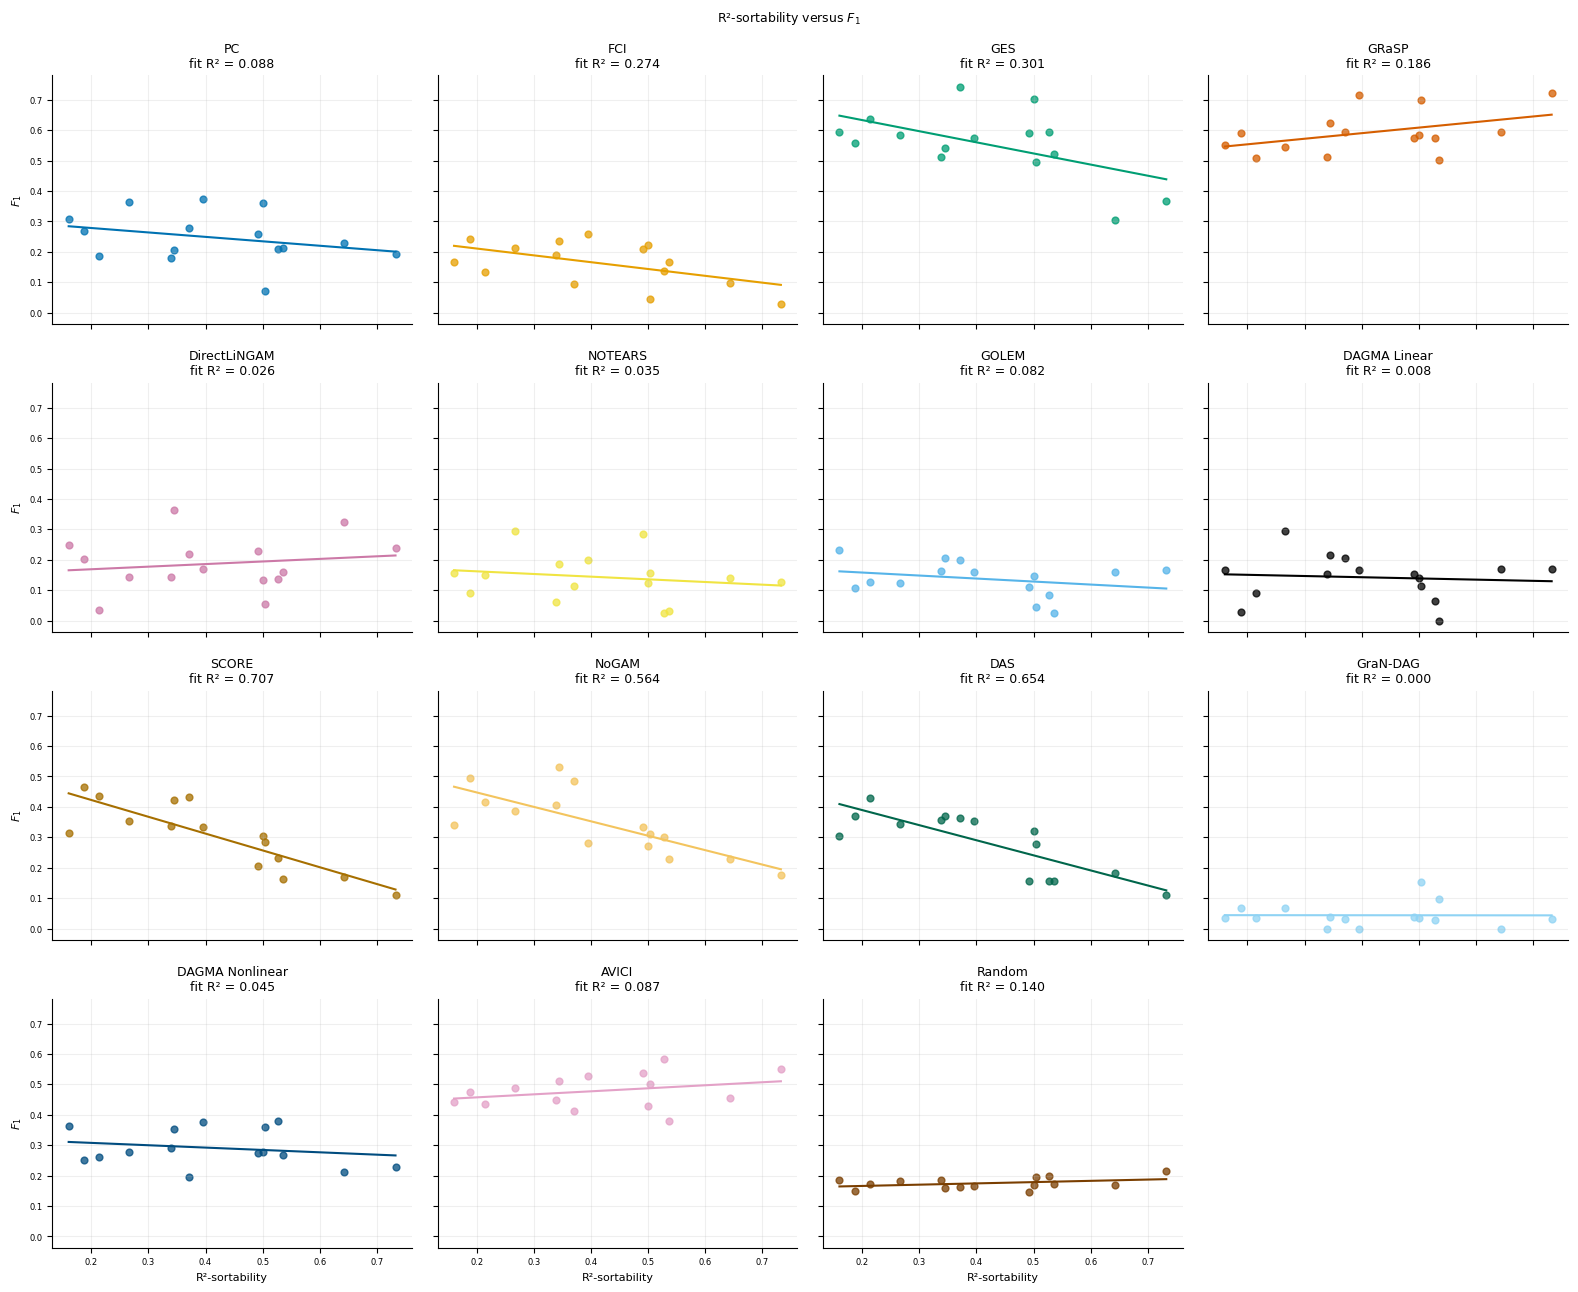

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,AVICI,0.453608,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
1,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,DAGMA_Linear,0.168421,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
2,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,DAGMA_Nonlinear,0.212176,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
3,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,DAS,0.183206,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
4,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,DirectLiNGAM,0.325581,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
5,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,FCI,0.096774,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
6,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,GES,0.304348,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
7,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,GOLEM,0.159292,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
8,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,GRaSP,0.594322,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
9,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,GraNDAG,0.000000,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,19,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
1,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,47,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.830189,0.535849,265,220,0,142,0,20,2000
2,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,50,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.857494,0.732187,407,349,0,298,0,20,2000
3,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,52,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.906250,0.503906,256,232,0,129,0,20,2000
4,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,71,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.682008,0.338912,239,163,0,81,0,20,2000
5,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,75,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.730878,0.371105,353,258,0,131,0,20,2000
6,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,77,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.675958,0.188153,287,194,0,54,0,20,2000
7,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,102,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.660232,0.266409,259,171,0,69,0,20,2000
8,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,125,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.889655,0.344828,145,129,0,50,0,20,2000
9,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,158,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.808290,0.160622,193,156,0,31,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,0.294455,0.086704,0.099434,0.437303,0.286726,0.260714,0.347979
1,DAGMA_Linear,15,-0.088629,0.007855,-0.039672,0.158575,0.753447,-0.076923,0.785253
2,DAGMA_Nonlinear,15,-0.212606,0.045201,-0.077600,0.323076,0.446808,-0.167857,0.549856
3,DAS,15,-0.808471,0.653625,-0.496416,0.488901,0.000264,-0.746429,0.001391
4,DirectLiNGAM,15,0.159770,0.025527,0.085188,0.151858,0.569506,0.050000,0.859541
5,FCI,15,-0.523321,0.273865,-0.224541,0.256022,0.045294,-0.461126,0.083621
6,GES,15,-0.548196,0.300519,-0.366121,0.706787,0.034363,-0.464286,0.081251
7,GOLEM,15,-0.286710,0.082203,-0.098913,0.177932,0.300180,-0.285714,0.301936
8,GRaSP,15,0.431710,0.186373,0.183212,0.517060,0.108086,0.371429,0.172850
9,GraNDAG,15,-0.004712,0.000022,-0.001125,0.044110,0.986703,-0.206653,0.459930


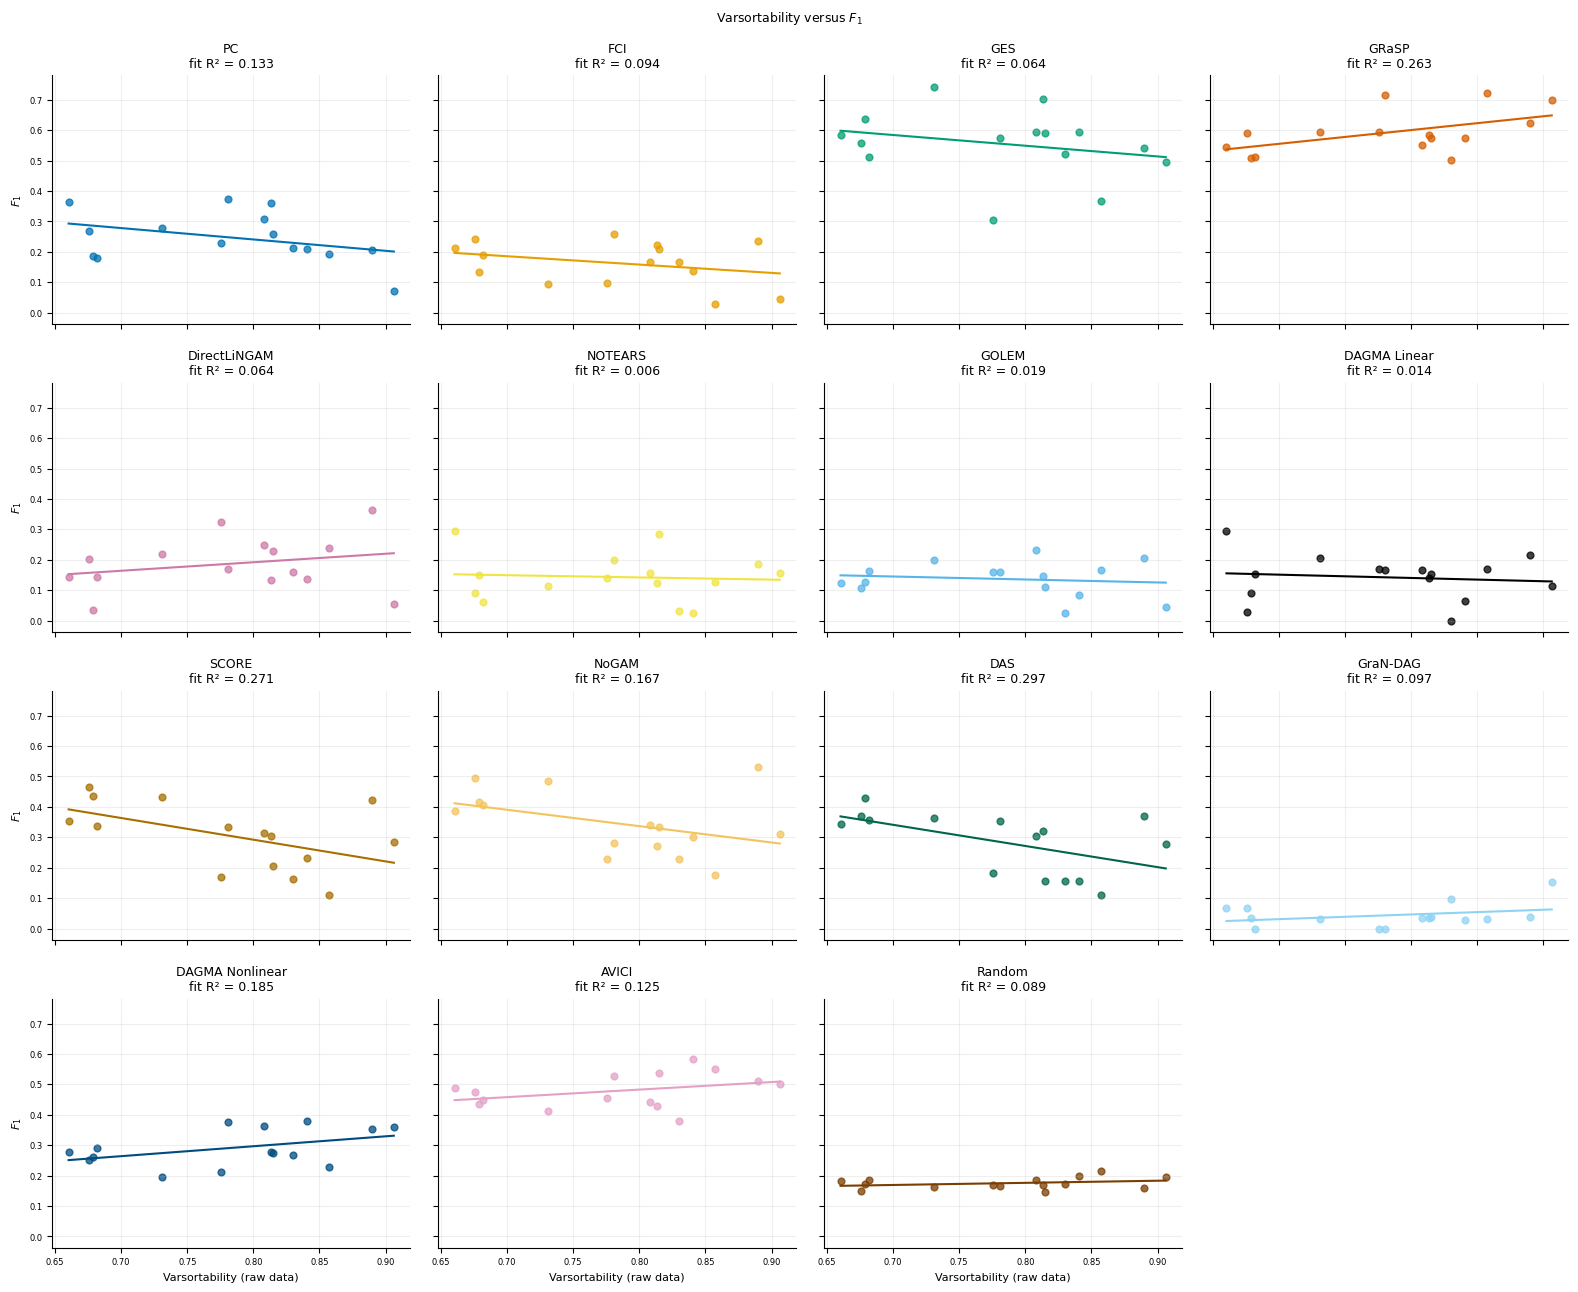

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,AVICI,0.453608,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
1,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,DAGMA_Linear,0.168421,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
2,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,DAGMA_Nonlinear,0.212176,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
3,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,DAS,0.183206,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
4,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,DirectLiNGAM,0.325581,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
5,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,FCI,0.096774,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
6,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,GES,0.304348,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
7,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,GOLEM,0.159292,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
8,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,GRaSP,0.594322,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
9,19,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,GraNDAG,0.000000,5,20,EB,0,0,Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,19,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.775510,0.642857,294,228,0,189,0,20,2000
1,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,47,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.830189,0.535849,265,220,0,142,0,20,2000
2,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,50,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.857494,0.732187,407,349,0,298,0,20,2000
3,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,52,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.906250,0.503906,256,232,0,129,0,20,2000
4,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,71,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.682008,0.338912,239,163,0,81,0,20,2000
5,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,75,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.730878,0.371105,353,258,0,131,0,20,2000
6,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,77,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.675958,0.188153,287,194,0,54,0,20,2000
7,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,102,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.660232,0.266409,259,171,0,69,0,20,2000
8,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,125,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.889655,0.344828,145,129,0,50,0,20,2000
9,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,158,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_Ga...,0.808290,0.160622,193,156,0,31,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,0.352976,0.124592,0.247920,0.284374,0.196879,0.396429,0.143495
1,DAGMA_Linear,15,-0.116452,0.013561,-0.108420,0.227033,0.679388,-0.105546,0.708135
2,DAGMA_Nonlinear,15,0.429743,0.184679,0.326247,0.035489,0.109881,0.328571,0.231810
3,DAS,15,-0.544583,0.296570,-0.695499,0.827839,0.035813,-0.539286,0.038022
4,DirectLiNGAM,15,0.252255,0.063633,0.279753,-0.031896,0.364399,0.150000,0.593630
5,FCI,15,-0.306919,0.094199,-0.273908,0.377477,0.265839,-0.280608,0.311037
6,GES,15,-0.253579,0.064303,-0.352253,0.830941,0.361800,-0.289286,0.295665
7,GOLEM,15,-0.136157,0.018539,-0.097701,0.213459,0.628494,-0.075000,0.790511
8,GRaSP,15,0.513064,0.263234,0.452882,0.238353,0.050479,0.417857,0.121173
9,GraNDAG,15,0.310729,0.096552,0.154300,-0.077170,0.259644,0.150946,0.591276


In [3]:
for study, frame in [("tuned", complete)]:
    frame = frame.loc[frame.dataset.eq('20nodes_EB_obsconf0_latconf0_Gaussian_Mixed')].copy()
    values = sortability(frame, study)
    arms = (
        [("untuned", frame)]
        if study == "benchmark"
        else list(frame.groupby("arm", observed=True))
    )
    for arm, arm_frame in arms:
        for family, group in arm_frame.groupby("dataset", observed=True):
            family_output = output / study / "by_family" / family / arm
            family_output.mkdir(parents=True, exist_ok=True)
            data = th.visualization_data(group)
            # F1 and SHD, precision and recall retain dataset-level blocks.
            for metric in ("f1", "SHD", "precision", "recall"):
                blocks = (
                    group.loc[group.finished]
                    .groupby(["dataset_seed", "model"])[metric]
                    .mean()
                    .reset_index()
                )
                summary = (
                    blocks.groupby("model")[metric].agg(["mean", "std", "size"]).reset_index()
                )
                display(summary.head(20))
            for metric in ("f1", "SHD"):
                fig, _, _ = fv.plot_metric_boxplot_grid(
                    data,
                    [{"title": family, "datasets": family}],
                    metric=metric,
                    coverage_policy="all",
                    ncols=1,
                    figsize=(10, 7),
                    font_size=9,
                )
                fig.savefig(family_output / f"{metric}.pdf", bbox_inches="tight")
                display(fig)
                plt.close(fig)
            # Stability only from recorded fits; invariant models remain zero.
            ok = group.loc[group.finished]
            model_range = (
                ok.groupby(["dataset_seed", "model"])
                .f1.agg(lambda v: v.max() - v.min())
                .rename("f1_range")
                .reset_index()
            )
            dataset_range = (
                ok.groupby(["model_seed", "model"])
                .f1.agg(lambda v: v.max() - v.min())
                .rename("f1_range")
                .reset_index()
            )
            for kind, table in [
                ("model_seed", model_range),
                ("dataset_seed", dataset_range),
            ]:
                display(table.head(20))
                summary = table.groupby("model").f1_range.mean().sort_values()
                fig, ax = plt.subplots(figsize=(8, 6))
                summary.rename(index=th.model_label).plot.barh(ax=ax)
                ax.set(
                    xlabel="Mean F1 range",
                    ylabel="",
                    title=f"{family}: {kind.replace('_', ' ')} variability",
                )
                fig.tight_layout()
                fig.savefig(family_output / f"{kind}_stability.pdf")
                display(fig)
                plt.close(fig)
            v = values.loc[values.dataset.eq(family)]
            for score in ("r2_sortability", "varsortability"):
                if v[score].notna().sum() < 3:
                    continue
                fig, _, details = fv.plot_varsortability_vs_f1(
                    data,
                    metric="f1",
                    datasets=family,
                    varsortability_values=v,
                    sortability=score,
                    coverage_policy="all",
                    columns=4,
                    include_r2_sort_regress=False,
                    obs_conf=None,
                    lat_conf=None,
                    font_size=8,
                    title_size=9,
                )
                fig.savefig(family_output / f"{score}.pdf", bbox_inches="tight")
                display(fig)
                plt.close(fig)
                for key, table in details.items():
                    if isinstance(table, pd.DataFrame):
                        display(table.head(20))
                blocks = (
                    ok.groupby(["dataset_seed", "model"])
                    .f1.mean()
                    .reset_index()
                    .merge(v, on="dataset_seed")
                )
                for model, g in blocks.groupby("model"):
                    valid = g[["f1", score]].dropna()
                    constant = valid.nunique().min() < 2
                    r = (
                        None
                        if len(valid) < 3 or constant
                        else spearmanr(valid[score], valid.f1)
                    )
                    correlations.append(
                        dict(
                            study=study,
                            arm=arm,
                            dataset=family,
                            model=model,
                            sortability=score,
                            n_pairs=len(valid),
                            rho=np.nan if r is None else r.statistic,
                            pvalue=np.nan if r is None else r.pvalue,
                            status="constant_or_insufficient" if r is None else "estimated",
                        )
                    )


In [4]:
corr = pd.DataFrame(correlations)
if len(corr):
    from statistical_methods import holm

    corr["pvalue_holm"] = np.nan
    valid = corr.pvalue.notna()
    corr.loc[valid, "pvalue_holm"] = (
        corr.loc[valid]
        .groupby(["study", "arm", "sortability"])
        .pvalue.transform(lambda p: holm(p))
    )
display(corr.head(20))


,study,arm,dataset,model,sortability,n_pairs,rho,pvalue,status,pvalue_holm
0,tuned,tuned,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,AVICI,r2_sortability,15,0.216265,0.438839,estimated,1.000000
1,tuned,tuned,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,DAGMA_Linear,r2_sortability,15,-0.428571,0.110960,estimated,1.000000
2,tuned,tuned,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,DAGMA_Nonlinear,r2_sortability,15,-0.728571,0.002065,estimated,0.024783
3,tuned,tuned,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,DAS,r2_sortability,15,-0.735714,0.001770,estimated,0.023008
4,tuned,tuned,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,DirectLiNGAM,r2_sortability,15,-0.003571,0.989921,estimated,1.000000
5,tuned,tuned,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,FCI,r2_sortability,15,-0.339286,0.216029,estimated,1.000000
6,tuned,tuned,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,GES,r2_sortability,15,-0.392857,0.147467,estimated,1.000000
7,tuned,tuned,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,GOLEM,r2_sortability,15,-0.042857,0.879460,estimated,1.000000
8,tuned,tuned,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,GRaSP,r2_sortability,15,0.371429,0.172850,estimated,1.000000
9,tuned,tuned,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,GraNDAG,r2_sortability,15,-0.371429,0.172850,estimated,1.000000
